## Quickstart

### Notebook Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Figures setup
plt.clf()  # needed otherwise `sns.set_theme` doesn't work
sns.set_theme(
    context="paper",
    style="whitegrid",
    palette="colorblind",
    rc={"figure.figsize": (5, 2)},
)

# Simplified int and float __repr__
np.set_printoptions(legacy="1.25")

<Figure size 640x480 with 0 Axes>

### Plotting discrete probability distirbutoins

Here is a simple example that shows how to plot
the probability mass function (PMF)
of poission distibution $P \sim \text{Pois}(\lambda=10)$.

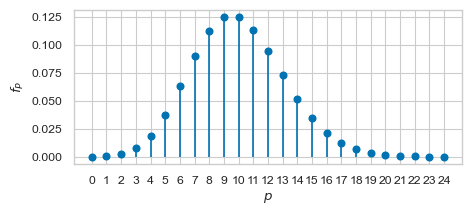

In [2]:
from scipy.stats import poisson
lam = 10
rvP = poisson(lam)

from ministats import plot_pmf
plot_pmf(rvP, xlims=[0,25], rv_name="P");

### Plotting continuous probability distirbutoins

Here is a simple example that shows how to plot
the probability density function (PDF)
of normal distibution $N \sim \mathcal{N}(\mu=100,\sigma=10)$.

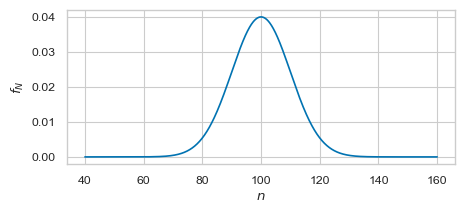

In [3]:
from scipy.stats import norm
rvN = norm(100,10)

from ministats import plot_pdf
plot_pdf(rvN, xlims=[40,160], rv_name="N");

### Computing sample statistics

We'll start by crearing a random sample of size $n=30$
from the normal distribution
$N \sim \mathcal{N}(\mu=100,\sigma=10)$.

In [4]:
from scipy.stats import norm
rvN = norm(100,10)

n = 30

np.random.seed(43)
sample = rvN.rvs(n)
sample

array([102.57399925,  90.91518567,  96.21496894,  94.65084401,
       108.58073346,  95.86990018, 104.98188584, 120.10199248,
       112.62861545,  95.60785143,  96.53562107, 104.5531966 ,
        83.31337293,  91.37914505, 104.92910848,  98.75686604,
       119.35136287,  93.81557345,  89.53161014,  91.10382411,
       100.14040537,  98.39170314, 122.30359649,  96.00884281,
       100.54444563, 108.84181815,  98.92019439, 105.55606984,
       103.94906636, 108.37205023])

In [5]:
from ministats import mean
mean(sample)

101.28079499555454

In [6]:
from ministats import var
var(sample)

86.42161227701393

In [7]:
from ministats import std
std(sample)

9.296322513607945

### Visualizing sampling distributions

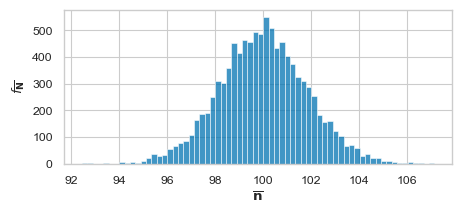

In [8]:
from ministats import gen_sampling_dist

nbars = gen_sampling_dist(rvN, estfunc=np.mean, n=30)
ax = sns.histplot(nbars)
ax.set_xlabel(r"$\overline{\mathbf{n}}$")
ax.set_ylabel(r"$f_{\overline{\mathbf{N}}}$");

### Confidence interval for the mean

In [9]:
from ministats import ci_mean
ci_mean(sample, method="a")

[98.39692019182347, 104.16466979928568]

In [10]:
from ministats import ci_mean
ci_mean(sample, method="b")

[98.67104310712713, 104.1143762353487]

### One-sample hypothesis test using simulation

In [11]:
from ministats import simulation_test_mean
simulation_test_mean(sample, mu0=100, sigma0=10)

0.4744

### One-sample $t$-test

In [12]:
from ministats import ttest_mean
ttest_mean(sample, mu0=100)

0.4565609669172723